In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define file paths 
path_casualties = './Dataset/dft-road-casualty-statistics-casualty-last-5-years.csv'
path_collisions = './Dataset/dft-road-casualty-statistics-collision-last-5-years.csv'
path_vehicles = './Dataset/dft-road-casualty-statistics-vehicle-last-5-years.csv'

# 2. Load the datasets (low_memory=False handles mixed types in large columns)
print("Loading files...")
collisions_df = pd.read_csv(path_collisions, low_memory=False)
vehicles_df = pd.read_csv(path_vehicles, low_memory=False)
casualties_df = pd.read_csv(path_casualties, low_memory=False)

print(f"Collisions shape: {collisions_df.shape}")
print(f"Vehicles shape: {vehicles_df.shape}")
print(f"Casualties shape: {casualties_df.shape}")

Loading files...
Collisions shape: (513801, 44)
Vehicles shape: (937265, 32)
Casualties shape: (652821, 24)


In [4]:
# information about the datasets
datasets = {
    "Collisions": collisions_df,
    "Vehicles": vehicles_df,
    "Casualties": casualties_df
}

for name, df in datasets.items() if hasattr(datasets, 'items') else datasets.items():
    print(f"\n{'='*20} DATASET: {name} {'='*20}")
    print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")

    # Missing values summary
    missing = df.isnull().sum()
    missing_pct = (missing / len(df)) * 100
    missing_df = pd.DataFrame({'Missing Count': missing, 'Missing Percentage (%)': missing_pct})
    missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values(by='Missing Percentage (%)', ascending=False)

    if not missing_df.empty:
        print("\nColumns with Missing Values:")
        print(missing_df.head(10)) # Print top 10 missing columns
    else:
        print("\nNo missing values found!")

    print("-" * 50)


==================== DATASET: Collisions ====================
Shape: 513801 rows, 44 columns

Columns with Missing Values:
                        Missing Count  Missing Percentage (%)
location_easting_osgr              53                0.010315
location_northing_osgr             53                0.010315
longitude                          53                0.010315
latitude                           53                0.010315
--------------------------------------------------

==================== DATASET: Vehicles ====================
Shape: 937265 rows, 32 columns

No missing values found!
--------------------------------------------------

==================== DATASET: Casualties ====================
Shape: 652821 rows, 24 columns

No missing values found!
--------------------------------------------------


Data Preprocessing

In [5]:
# since missing values are very very less => drop that records
# Check shape before dropping
print(f"Collisions shape BEFORE dropping: {collisions_df.shape}")

# Drop rows where latitude or longitude is missing
collisions_df = collisions_df.dropna(subset=['latitude', 'longitude', 'location_easting_osgr', 'location_northing_osgr'])

# Check shape after dropping (should be exactly 2 rows less: 101,523)
print(f"Collisions shape AFTER dropping:  {collisions_df.shape}")

# Final sanity check for missing values across all datasets
print("\n--- Post-Cleaning Missing Value Check ---")
print("Collisions missing:", collisions_df[['latitude', 'longitude']].isnull().sum().sum())
print("Vehicles missing:   ", vehicles_df.isnull().sum().sum())
print("Casualties missing: ", casualties_df.isnull().sum().sum())

Collisions shape BEFORE dropping: (513801, 44)
Collisions shape AFTER dropping:  (513748, 44)

--- Post-Cleaning Missing Value Check ---
Collisions missing: 0
Vehicles missing:    0
Casualties missing:  0


In [6]:
# Print columns for Collisions dataset
print("--- Collisions Dataset Columns ---")
print(collisions_df.columns.tolist())
print(f"Total columns: {len(collisions_df.columns)}\n")

# Print columns for Vehicles dataset
print("--- Vehicles Dataset Columns ---")
print(vehicles_df.columns.tolist())
print(f"Total columns: {len(vehicles_df.columns)}\n")

# Print columns for Casualties dataset
print("--- Casualties Dataset Columns ---")
print(casualties_df.columns.tolist())
print(f"Total columns: {len(casualties_df.columns)}")

--- Collisions Dataset Columns ---
['collision_index', 'collision_year', 'collision_ref_no', 'location_easting_osgr', 'location_northing_osgr', 'longitude', 'latitude', 'police_force', 'collision_severity', 'number_of_vehicles', 'number_of_casualties', 'date', 'day_of_week', 'time', 'local_authority_district', 'local_authority_ons_district', 'local_authority_highway', 'local_authority_highway_current', 'first_road_class', 'first_road_number', 'road_type', 'speed_limit', 'junction_detail_historic', 'junction_detail', 'junction_control', 'second_road_class', 'second_road_number', 'pedestrian_crossing_human_control_historic', 'pedestrian_crossing_physical_facilities_historic', 'pedestrian_crossing', 'light_conditions', 'weather_conditions', 'road_surface_conditions', 'special_conditions_at_site', 'carriageway_hazards_historic', 'carriageway_hazards', 'urban_or_rural_area', 'did_police_officer_attend_scene_of_accident', 'trunk_road_flag', 'lsoa_of_accident_location', 'enhanced_severity_col

## EDA on Individual Datasets

1. Collisions Dataset EDA



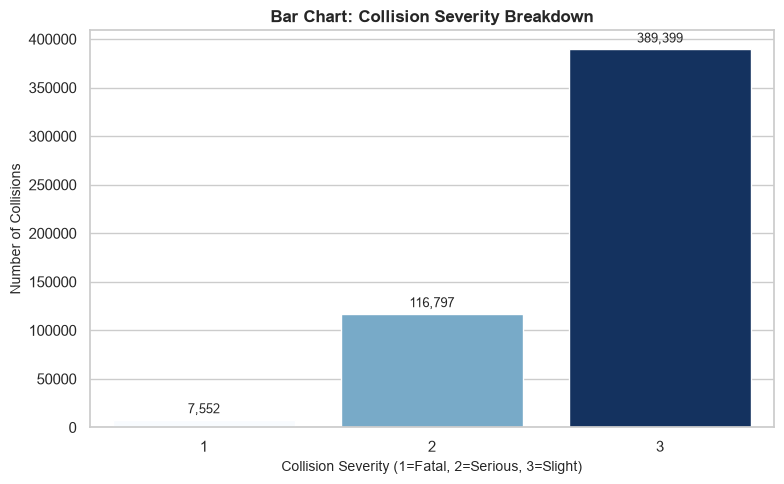

In [5]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))

ax = sns.countplot(x='collision_severity', data=collisions_df, hue='collision_severity', palette='Blues', legend=False, order=[1, 2, 3])
plt.title('Bar Chart: Collision Severity Breakdown', fontsize=12, fontweight='bold')
plt.xlabel('Collision Severity (1=Fatal, 2=Serious, 3=Slight)', fontsize=10)
plt.ylabel('Number of Collisions', fontsize=10)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height):,}', (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

# Reveals a severe class imbalance where "Slight" accidents overwhelmingly dominate the dataset, while "Serious" and "Fatal" incidents represent a small fraction.

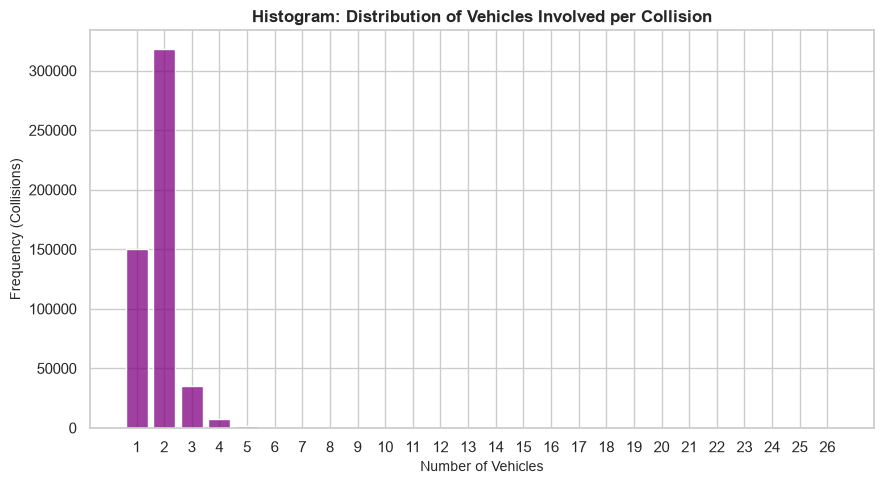

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.histplot(collisions_df['number_of_vehicles'], discrete=True, color='purple', shrink=0.8)
plt.title('Histogram: Distribution of Vehicles Involved per Collision', fontsize=12, fontweight='bold')
plt.xlabel('Number of Vehicles', fontsize=10)
plt.ylabel('Frequency (Collisions)', fontsize=10)

# Fix x-axis ticks to only show whole numbers based on the actual data range
max_vehicles = int(collisions_df['number_of_vehicles'].max())
plt.xticks(range(1, max_vehicles + 1))

plt.tight_layout()
plt.show(

)

# Purpose: To examine the structural complexity of accidents by checking whether crashes involve single vehicles or multi-vehicle chains.

# Inference: Demonstrates that the vast majority of collisions involve either 1 or 2 vehicles, indicating that most road incidents stem from single-vehicle driver errors or two-car interactions rather than massive multi-vehicle pileups.

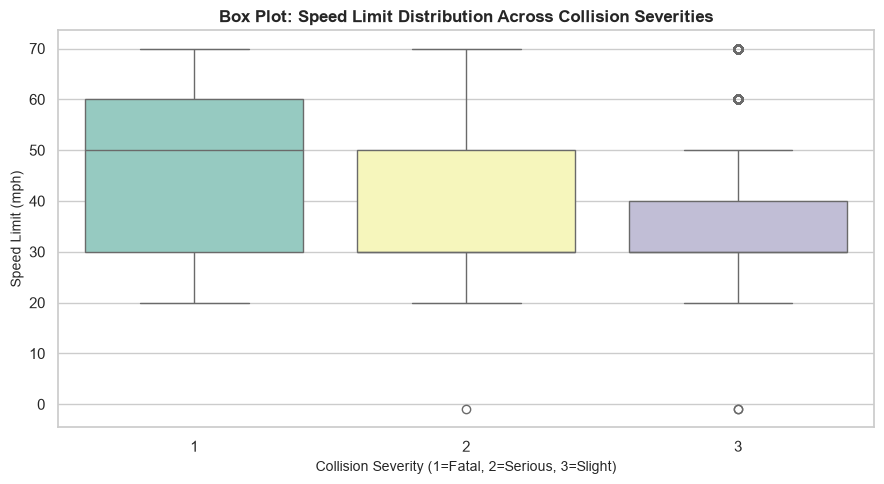

In [7]:
plt.figure(figsize=(9, 5))

sns.boxplot(x='collision_severity', y='speed_limit', data=collisions_df, palette='Set3', order=[1, 2, 3], hue='collision_severity', legend=False)
plt.title('Box Plot: Speed Limit Distribution Across Collision Severities', fontsize=12, fontweight='bold')
plt.xlabel('Collision Severity (1=Fatal, 2=Serious, 3=Slight)', fontsize=10)
plt.ylabel('Speed Limit (mph)', fontsize=10)

plt.tight_layout()
plt.show()

# Highlights that fatal and serious accidents frequently map to higher-speed zones (such as rural 50–60 mph roads), whereas slight accidents cluster heavily in urban 30 mph zones, confirming speed as a primary risk factor.

2. Vehicle Dataset EDA

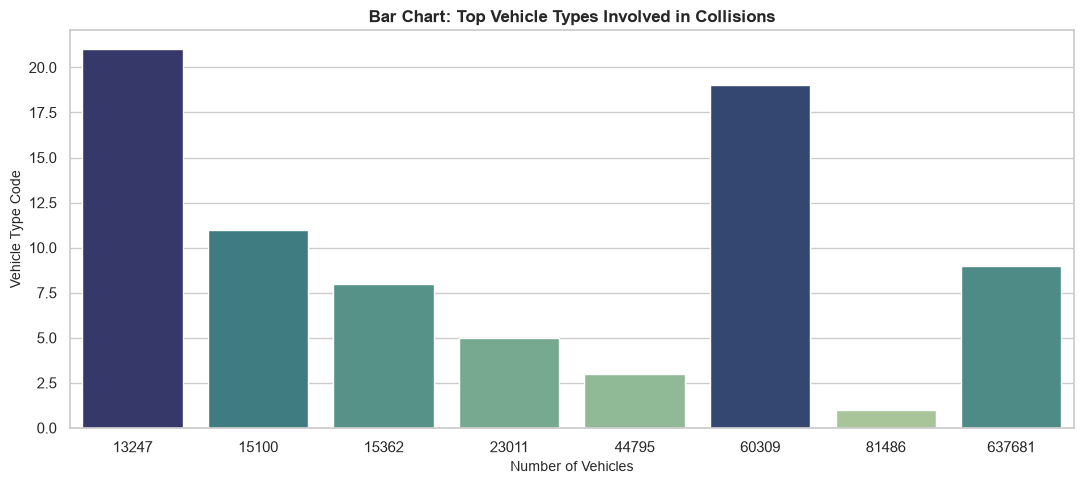

In [8]:
plt.figure(figsize=(11, 5))

top_vehicles = vehicles_df['vehicle_type'].value_counts().head(8).reset_index()
top_vehicles.columns = ['vehicle_type', 'count']

ax = sns.barplot(data=top_vehicles, x='count', y='vehicle_type', palette='crest', hue='vehicle_type', legend=False)
plt.title('Bar Chart: Top Vehicle Types Involved in Collisions', fontsize=12, fontweight='bold')
plt.xlabel('Number of Vehicles', fontsize=10)
plt.ylabel('Vehicle Type Code', fontsize=10)

plt.tight_layout()
plt.show()

# Shows that standard passenger cars form the vast majority of accident-involved vehicles due to high market exposure, followed by commercial transport and two-wheeled vehicles, pointing toward exposure-based risk patterns.

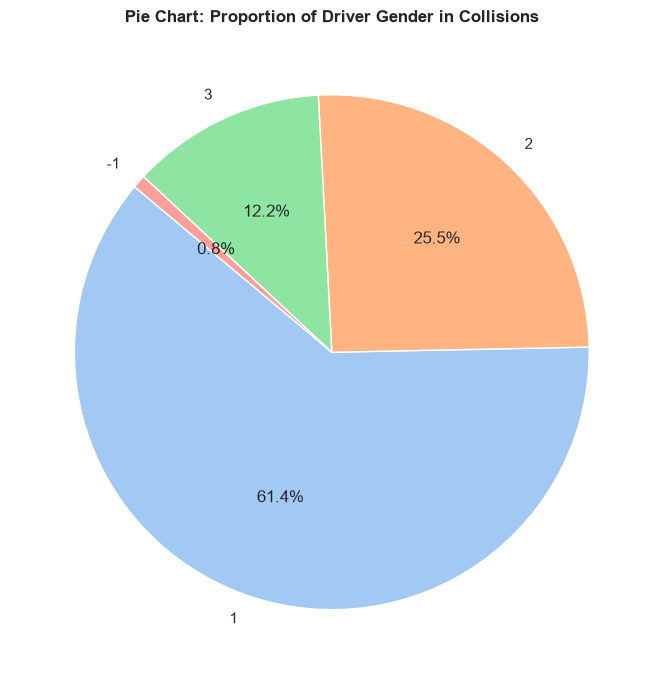

In [9]:
plt.figure(figsize=(7, 7))

# Map codes if applicable, or count raw values (typically 1=Male, 2=Female, 3=Not known)
gender_counts = vehicles_df['sex_of_driver'].value_counts()

plt.pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title('Pie Chart: Proportion of Driver Gender in Collisions', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

# Establishes the baseline demographic representation of drivers involved in accidents, providing a reference point for analyzing behavioral or exposure differences between genders.

3. Casualties Dataset EDA


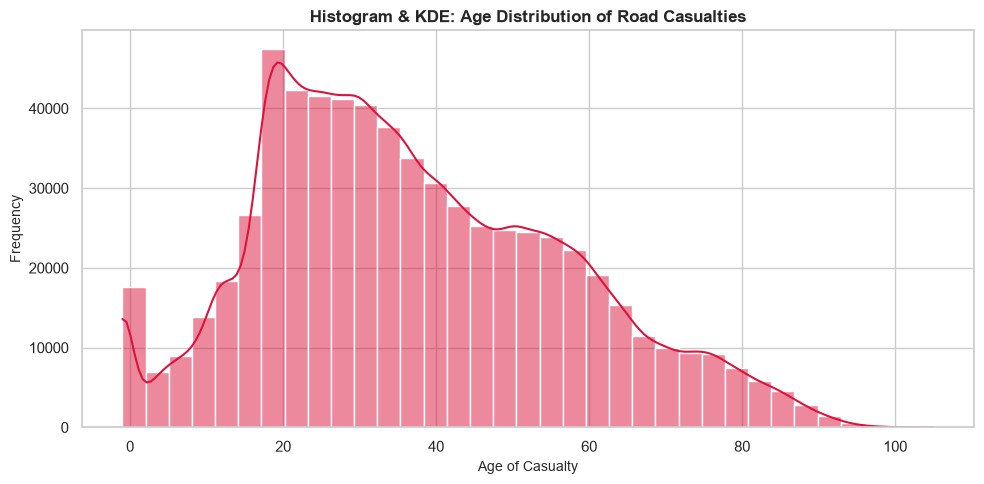

In [10]:
plt.figure(figsize=(10, 5))

sns.histplot(casualties_df['age_of_casualty'].dropna(), bins=35, kde=True, color='crimson')
plt.title('Histogram & KDE: Age Distribution of Road Casualties', fontsize=12, fontweight='bold')
plt.xlabel('Age of Casualty', fontsize=10)
plt.ylabel('Frequency', fontsize=10)

plt.tight_layout()
plt.show()

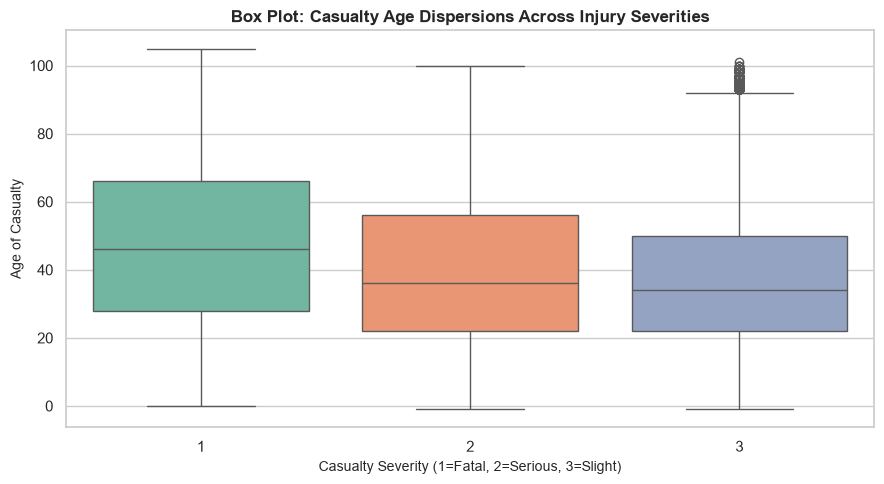

In [11]:
plt.figure(figsize=(9, 5))

sns.boxplot(x='casualty_severity', y='age_of_casualty', data=casualties_df, palette='Set2', order=[1, 2, 3], hue='casualty_severity', legend=False)
plt.title('Box Plot: Casualty Age Dispersions Across Injury Severities', fontsize=12, fontweight='bold')
plt.xlabel('Casualty Severity (1=Fatal, 2=Serious, 3=Slight)', fontsize=10)
plt.ylabel('Age of Casualty', fontsize=10)

plt.tight_layout()
plt.show()

# Demonstrates that median victim ages shift across injury tiers, often showing older median ages associated with fatal outcomes due to lower physiological resilience.

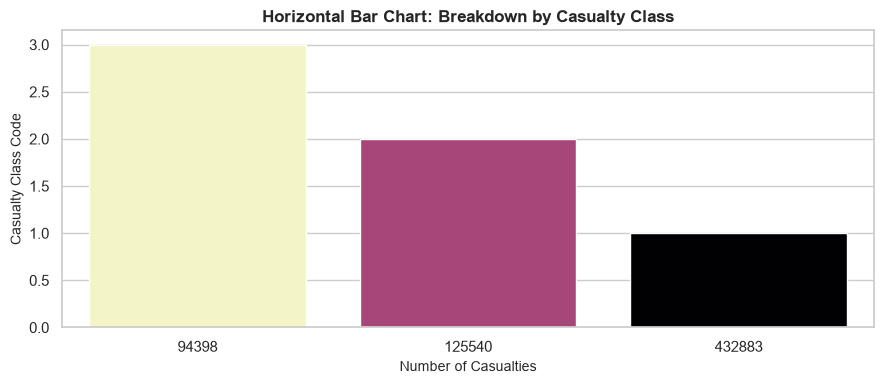

In [12]:
plt.figure(figsize=(9, 4))

class_counts = casualties_df['casualty_class'].value_counts().reset_index()
class_counts.columns = ['casualty_class', 'count']

ax = sns.barplot(data=class_counts, x='count', y='casualty_class', palette='magma', hue='casualty_class', legend=False)
plt.title('Horizontal Bar Chart: Breakdown by Casualty Class', fontsize=12, fontweight='bold')
plt.xlabel('Number of Casualties', fontsize=10)
plt.ylabel('Casualty Class Code', fontsize=10)

plt.tight_layout()
plt.show()

EDA on Merged Dataset

In [13]:

# Aggregate vehicle-level information
# Unknown/invalid age values are excluded from age statistics.

veh_work = vehicles_df.copy()

veh_work["age_of_driver_clean"] = (
    pd.to_numeric(veh_work["age_of_driver"], errors="coerce")
    .where(lambda s: s.between(16, 100))
)

# Check these vehicle-type codes against your STATS19 data guide
MOTORCYCLE = {2, 3, 4, 5, 23, 97, 103, 104, 105, 106}
HGV = {20, 21, 98, 113}
BUS = {11, 108, 109}

veh_work["is_motorcycle"] = veh_work["vehicle_type"].isin(MOTORCYCLE)
veh_work["is_hgv"] = veh_work["vehicle_type"].isin(HGV)
veh_work["is_bus"] = veh_work["vehicle_type"].isin(BUS)
veh_work["is_cycle"] = veh_work["vehicle_type"].eq(1)
veh_work["is_van"] = veh_work["vehicle_type"].eq(19)

vehicle_summary = veh_work.groupby("collision_index").agg(
    vehicle_records=("vehicle_reference", "count"),
    distinct_vehicle_types=("vehicle_type", "nunique"),
    mean_driver_age=("age_of_driver_clean", "mean"),
    motorcycle_involved=("is_motorcycle", "any"),
    hgv_involved=("is_hgv", "any"),
    bus_involved=("is_bus", "any"),
    cycle_involved=("is_cycle", "any"),
    van_involved=("is_van", "any")
)

print("Vehicle summary shape:", vehicle_summary.shape)
display(vehicle_summary.head())


Vehicle summary shape: (513801, 8)


,vehicle_records,distinct_vehicle_types,mean_driver_age,motorcycle_involved,hgv_involved,bus_involved,cycle_involved,van_involved
collision_index,,,,,,,,
2021010287148,3,1,19.0,False,False,False,False,False
2021010287149,2,1,26.5,False,False,False,False,False
2021010287151,2,1,27.0,False,False,False,False,False
2021010287155,1,1,NaN,False,False,False,False,False
2021010287157,4,1,37.0,False,False,False,False,False


In [14]:

cas_work = casualties_df.copy()

cas_work["age_of_casualty_clean"] = (
    pd.to_numeric(cas_work["age_of_casualty"], errors="coerce")
    .where(lambda s: s.between(0, 110))
)

cas_work["is_pedestrian"] = cas_work["casualty_class"].eq(3)
cas_work["is_child"] = cas_work["age_band_of_casualty"].isin([1, 2, 3])
cas_work["is_elderly"] = cas_work["age_band_of_casualty"].isin([10, 11])

casualty_summary = cas_work.groupby("collision_index").agg(
    casualty_records=("casualty_reference", "count"),
    mean_casualty_age=("age_of_casualty_clean", "mean"),
    youngest_casualty_age=("age_of_casualty_clean", "min"),
    pedestrian_casualty=("is_pedestrian", "any"),
    child_casualty=("is_child", "any"),
    elderly_casualty=("is_elderly", "any")
)

# Counts by casualty injury severity
severity_counts = pd.crosstab(
    cas_work["collision_index"],
    cas_work["casualty_severity"]
)

severity_counts.columns = [
    f"casualties_severity_code_{int(c)}"
    for c in severity_counts.columns
]

casualty_summary = casualty_summary.join(
    severity_counts, how="left"
)

print("Casualty summary shape:", casualty_summary.shape)
display(casualty_summary.head())


Casualty summary shape: (513801, 9)


,casualty_records,mean_casualty_age,youngest_casualty_age,pedestrian_casualty,child_casualty,elderly_casualty,casualties_severity_code_1,casualties_severity_code_2,casualties_severity_code_3
collision_index,,,,,,,,,
2021010287148,1,19.0,19.0,False,False,False,0,0,1
2021010287149,3,21.0,17.0,False,False,False,0,1,2
2021010287151,4,25.5,20.0,False,False,False,0,1,3
2021010287155,1,49.0,49.0,True,False,False,1,0,0
2021010287157,1,37.0,37.0,False,False,False,0,0,1


In [15]:

# IMPORTANT:
# Use the original collision dataset for the main analysis.
# If you previously dropped rows due to missing coordinates, reload the
# original CSV before running this cell to avoid excluding those collisions.

col_work = collisions_df.copy()

for df in [col_work, vehicle_summary, casualty_summary]:
    # Normalize key format consistently
    pass

col_work["collision_index"] = (
    col_work["collision_index"].astype("string").str.strip()
)

vehicle_summary.index = (
    vehicle_summary.index.astype("string").str.strip()
)
casualty_summary.index = (
    casualty_summary.index.astype("string").str.strip()
)

# Verify the collision table is unique before merging
assert col_work["collision_index"].is_unique, (
    "Collision IDs are not unique. Investigate duplicates first."
)

df_merged = (
    col_work
    .merge(
        vehicle_summary,
        left_on="collision_index",
        right_index=True,
        how="left",
        validate="one_to_one"
    )
    .merge(
        casualty_summary,
        left_on="collision_index",
        right_index=True,
        how="left",
        validate="one_to_one"
    )
)

print("Original collision shape:", col_work.shape)
print("Merged dataset shape:", df_merged.shape)
print("Unique collision IDs:", df_merged["collision_index"].nunique())
print("Duplicate collision IDs:", df_merged["collision_index"].duplicated().sum())

print("\nMerged dataset preview:")
display(df_merged.head())

print("\nMissing values in merged dataset (top 20):")
display(
    df_merged.isna().sum()
    .sort_values(ascending=False)
    .head(20)
    .to_frame("missing_count")
)

Original collision shape: (513748, 44)
Merged dataset shape: (513748, 61)
Unique collision IDs: 513748
Duplicate collision IDs: 0

Merged dataset preview:


,collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,...,van_involved,casualty_records,mean_casualty_age,youngest_casualty_age,pedestrian_casualty,child_casualty,elderly_casualty,casualties_severity_code_1,casualties_severity_code_2,casualties_severity_code_3
0,202417H105824,2024,17H105824,448628.0,533968.0,-1.24700,54.69840,17,2,2,...,False,1,33.000000,33.0,False,False,False,0,1,0
1,202517M115025,2025,17M115025,452379.0,519038.0,-1.19147,54.56387,17,2,2,...,False,1,17.000000,17.0,False,False,False,0,1,0
2,202517L306225,2025,17L306225,459273.0,523811.0,-1.08390,54.60600,17,3,2,...,True,3,19.666667,10.0,False,True,False,0,0,3
3,202417S104724,2024,17S104724,440460.0,517548.0,-1.37599,54.55157,17,3,2,...,False,2,23.500000,22.0,False,False,False,0,0,2
4,202517S106525,2025,17S106525,444331.0,518776.0,-1.31596,54.56228,17,2,2,...,False,1,16.000000,16.0,False,False,False,0,1,0



Missing values in merged dataset (top 20):


,missing_count
mean_driver_age,30396
mean_casualty_age,8392
youngest_casualty_age,8392
collision_year,0
collision_index,0
longitude,0
latitude,0
police_force,0
collision_severity,0
number_of_vehicles,0


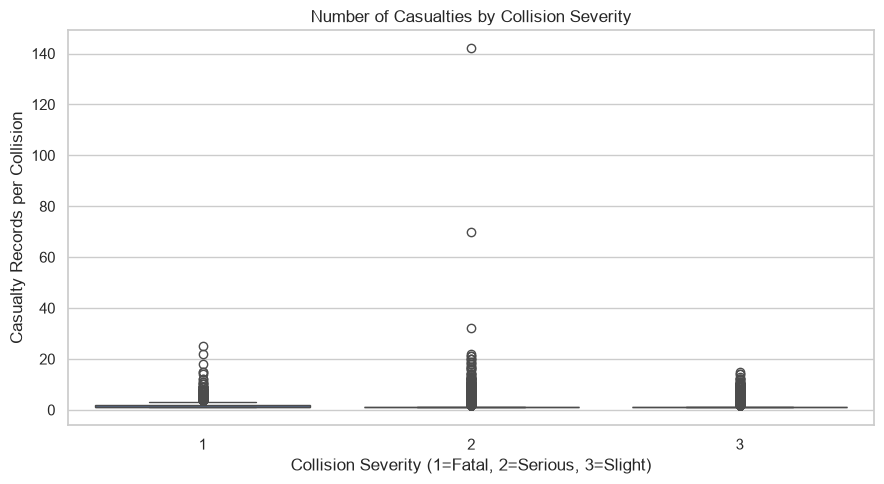

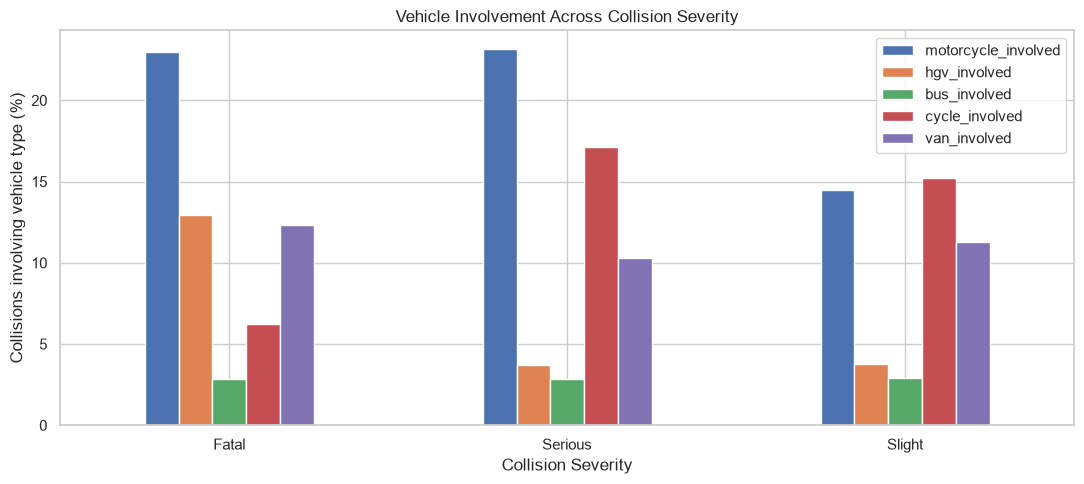

Percentage of collisions with pedestrian casualties by severity:


,percentage
collision_severity,
1,25.529661
2,23.022852
3,15.895521


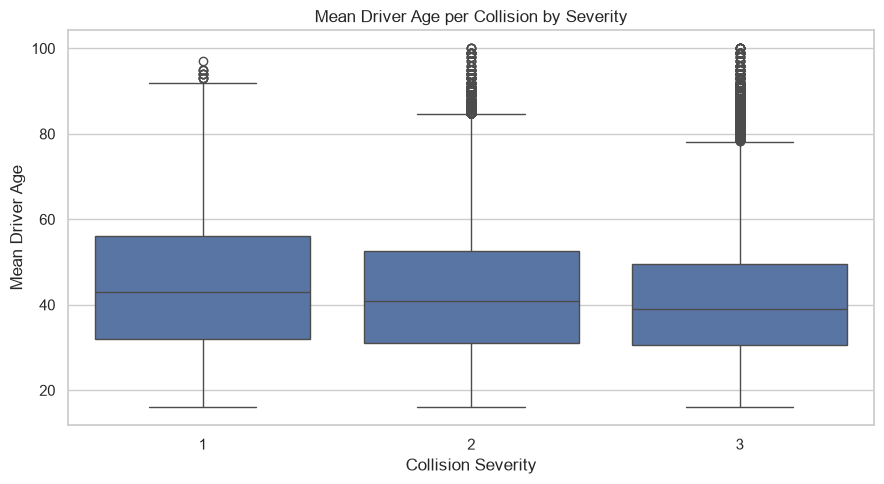

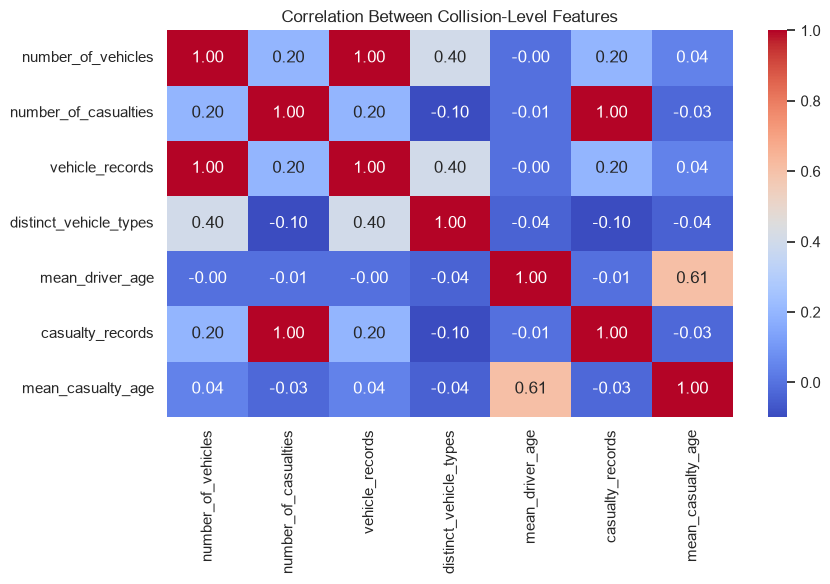

In [16]:
# EDA on Merged dataset
# 1. Collision severity versus number of casualties

plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df_merged,
    x="collision_severity",
    y="casualty_records"
)
plt.title("Number of Casualties by Collision Severity")
plt.xlabel("Collision Severity (1=Fatal, 2=Serious, 3=Slight)")
plt.ylabel("Casualty Records per Collision")
plt.tight_layout()
plt.show()


# 2. Severity versus involvement of different vehicle types

vehicle_flags = [
    "motorcycle_involved", "hgv_involved", "bus_involved",
    "cycle_involved", "van_involved"
]

severity_by_vehicle = df_merged.groupby(
    "collision_severity"
)[vehicle_flags].mean() * 100

severity_by_vehicle.index = severity_by_vehicle.index.map({
    1: "Fatal", 2: "Serious", 3: "Slight"
})

severity_by_vehicle.plot(
    kind="bar", figsize=(11, 5)
)
plt.title("Vehicle Involvement Across Collision Severity")
plt.xlabel("Collision Severity")
plt.ylabel("Collisions involving vehicle type (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# 3. Severity versus pedestrian involvement

pedestrian_rates = (
    df_merged.groupby("collision_severity")["pedestrian_casualty"]
    .mean() * 100
)

print("Percentage of collisions with pedestrian casualties by severity:")
display(pedestrian_rates.to_frame("percentage"))


# 4. Driver age distribution by severity

plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df_merged,
    x="collision_severity",
    y="mean_driver_age"
)
plt.title("Mean Driver Age per Collision by Severity")
plt.xlabel("Collision Severity")
plt.ylabel("Mean Driver Age")
plt.tight_layout()
plt.show()


# 5. Correlation among selected numerical features

numeric_cols = [
    "number_of_vehicles", "number_of_casualties",
    "vehicle_records", "distinct_vehicle_types",
    "mean_driver_age", "casualty_records",
    "mean_casualty_age"
]

plt.figure(figsize=(9, 6))
sns.heatmap(
    df_merged[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Collision-Level Features")
plt.tight_layout()
plt.show()

## Build the transaction table (one row = one collision)

Why not the full merge? A collision with 3 vehicles and 2 casualties would appear as many rows,
so its attributes get counted several times and every support value is inflated/biased.
Instead we aggregate vehicles and casualties up to the collision level.

Rules followed here:
- Every item is `Attribute=Value`. Unknown codes (-1, 9, 99, ...) become NaN so they never turn into items.
- Rare flags (motorcycle involved, pedestrian casualty, ...) are added only when True.
- Excluded on purpose: IDs, coordinates, LSOA / local-authority columns (too many distinct values) and
  `enhanced_severity_collision`, `collision_injury_based`, `collision_adjusted_severity_*`
  (these are re-encodings of severity, they would give trivial rules).

In [17]:
import numpy as np, pandas as pd

col = collisions_df.set_index('collision_index')
veh = vehicles_df
cas = casualties_df

def m(series, mapping, name):
    # code -> 'Name=Label'; anything not in mapping (unknown) -> NaN
    return series.map(mapping).map(lambda v: f"{name}={v}" if pd.notna(v) else np.nan)

items = pd.DataFrame(index=col.index)

# ---- target ----
items['sev'] = m(col['collision_severity'], {1:'Fatal', 2:'Serious', 3:'Slight'}, 'Severity')

# ---- road / environment ----
items['speed'] = col['speed_limit'].where(col['speed_limit'] > 0).map(lambda v: f"Speed={int(v)}mph" if pd.notna(v) else np.nan)
items['light'] = m(col['light_conditions'], {1:'Daylight', 4:'Dark_streetlit', 5:'Dark_unlit', 6:'Dark_unlit'}, 'Light')
items['weather'] = m(col['weather_conditions'], {1:'Fine', 2:'Rain', 3:'Snow', 4:'HighWind', 5:'HighWind', 6:'HighWind', 7:'Fog'}, 'Weather')
items['surface'] = m(col['road_surface_conditions'], {1:'Dry', 2:'Wet', 3:'Snow_Ice', 4:'Snow_Ice', 5:'Flood'}, 'Surface')
items['area'] = m(col['urban_or_rural_area'], {1:'Urban', 2:'Rural'}, 'Area')
items['roadtype'] = m(col['road_type'], {1:'Roundabout', 2:'OneWay', 3:'DualCarriageway', 6:'SingleCarriageway', 7:'SlipRoad', 12:'OneWay_Slip'}, 'RoadType')
items['junction'] = m(col['junction_detail'], {0:'None', 1:'Roundabout', 2:'MiniRoundabout', 3:'T_Junction', 5:'SlipRoad', 6:'Crossroads', 7:'MultiArm', 8:'PrivateDrive', 9:'Other'}, 'Junction')
items['roadclass'] = m(col['first_road_class'], {1:'Motorway', 2:'A(M)', 3:'A', 4:'B', 5:'C', 6:'Unclassified'}, 'RoadClass')

# ---- time ----
hour = pd.to_numeric(col['time'].astype(str).str[:2], errors='coerce')
items['time'] = pd.cut(hour, bins=[-1, 5, 9, 15, 19, 23],
                       labels=['Night(0-5)', 'MorningPeak(6-9)', 'Midday(10-15)', 'EveningPeak(16-19)', 'LateEvening(20-23)']
                      ).astype(object).map(lambda v: f"Time={v}" if pd.notna(v) else np.nan)
items['daytype'] = col['day_of_week'].map({1:'Weekend', 7:'Weekend', 2:'Weekday', 3:'Weekday', 4:'Weekday', 5:'Weekday', 6:'Weekday'}).map(lambda v: f"Day={v}" if pd.notna(v) else np.nan)
month = pd.to_datetime(col['date'], dayfirst=True, errors='coerce').dt.month
items['season'] = month.map({12:'Winter', 1:'Winter', 2:'Winter', 3:'Spring', 4:'Spring', 5:'Spring',
                             6:'Summer', 7:'Summer', 8:'Summer', 9:'Autumn', 10:'Autumn', 11:'Autumn'}).map(lambda v: f"Season={v}" if pd.notna(v) else np.nan)

# ---- size of collision ----
items['nveh'] = col['number_of_vehicles'].clip(upper=3).map({1:'1', 2:'2', 3:'3+'}).map(lambda v: f"Vehicles={v}" if pd.notna(v) else np.nan)
items['ncas'] = col['number_of_casualties'].clip(upper=3).map({1:'1', 2:'2', 3:'3+'}).map(lambda v: f"Casualties={v}" if pd.notna(v) else np.nan)

# ---- vehicle-level -> collision-level flags (item only when True) ----
# NOTE: verify these codes against the DfT STATS19 guide shipped with your dataset.
MOTORCYCLE = {2, 3, 4, 5, 23, 97, 103, 104, 105, 106}
HGV        = {20, 21, 98, 113}
BUS        = {11, 108, 109}
v = veh.copy()
v['f_motorcycle'] = v['vehicle_type'].isin(MOTORCYCLE)
v['f_cycle']      = v['vehicle_type'].eq(1)
v['f_hgv']        = v['vehicle_type'].isin(HGV)
v['f_bus']        = v['vehicle_type'].isin(BUS)
v['f_van']        = v['vehicle_type'].eq(19)
v['f_young_drv']  = v['age_band_of_driver'].isin([4, 5])        # 16-25
v['f_old_drv']    = v['age_band_of_driver'].isin([10, 11])      # 66+
v['f_skid']       = v['skidding_and_overturning'].gt(0)
v['f_left_road']  = v['vehicle_leaving_carriageway'].gt(0)
v['f_hit_offroad']= v['hit_object_off_carriageway'].gt(0)
vflags = v.groupby('collision_index')[[c for c in v.columns if c.startswith('f_')]].any()
vnames = {'f_motorcycle':'Motorcycle_involved', 'f_cycle':'Cycle_involved', 'f_hgv':'HGV_involved', 'f_bus':'Bus_involved',
          'f_van':'Van_involved', 'f_young_drv':'YoungDriver(16-25)', 'f_old_drv':'OlderDriver(66+)',
          'f_skid':'Skid_or_Overturn', 'f_left_road':'LeftCarriageway', 'f_hit_offroad':'HitObjectOffRoad'}

# ---- casualty-level -> collision-level flags ----
c2 = cas.copy()
c2['f_ped_cas']   = c2['casualty_class'].eq(3)
c2['f_child_cas'] = c2['age_band_of_casualty'].isin([1, 2, 3])   # 0-15
c2['f_old_cas']   = c2['age_band_of_casualty'].isin([10, 11])    # 66+
cflags = c2.groupby('collision_index')[['f_ped_cas', 'f_child_cas', 'f_old_cas']].any()
cnames = {'f_ped_cas':'Pedestrian_casualty', 'f_child_cas':'Child_casualty', 'f_old_cas':'Elderly_casualty'}

# ---- one-hot ----
cat_part = pd.get_dummies(items, prefix='', prefix_sep='', dtype=bool)
flag_part = (vflags.rename(columns=vnames).reindex(col.index, fill_value=False)
             .join(cflags.rename(columns=cnames).reindex(col.index, fill_value=False)))
basket = pd.concat([cat_part, flag_part], axis=1).astype(bool)

# drop ultra-rare items (<0.1%) - they can never be frequent anyway and just slow Apriori
keep = basket.columns[basket.mean() >= 0.001]
basket = basket[keep]
N = len(basket)
print("transactions:", N, "| items:", basket.shape[1], "| avg items per transaction:", round(basket.sum(axis=1).mean(), 1))
print(basket.mean().sort_values(ascending=False).round(3).to_string())

transactions: 513748 | items: 65 | avg items per transaction: 15.3
Casualties=1                  0.815
Weather=Fine                  0.805
Severity=Slight               0.758
Day=Weekday                   0.750
Surface=Dry                   0.728
RoadType=SingleCarriageway    0.726
Light=Daylight                0.717
Area=Urban                    0.672
Vehicles=2                    0.619
Speed=30mph                   0.520
Junction=None                 0.491
RoadClass=A                   0.440
Time=Midday(10-15)            0.359
RoadClass=Unclassified        0.359
Area=Rural                    0.328
Time=EveningPeak(16-19)       0.295
Vehicles=1                    0.293
YoungDriver(16-25)            0.269
Season=Autumn                 0.268
Season=Summer                 0.261
LeftCarriageway               0.253
Skid_or_Overturn              0.251
Day=Weekend                   0.250
Season=Spring                 0.244
Surface=Wet                   0.235
Severity=Serious              0.2

In [18]:

print("TRANSACTION DATASET VALIDATION")
print("-" * 45)

print("Transactions:", len(basket))
print("Items:", basket.shape[1])
print("Missing cells:", basket.isna().sum().sum())
print("Duplicate collision IDs:", basket.index.duplicated().sum())
print("Duplicate item names:", basket.columns.duplicated().sum())
print("Empty transactions:", (~basket.any(axis=1)).sum())

print("\nMost frequent items (% of transactions):")
display(
    (basket.mean() * 100)
    .sort_values(ascending=False)
    .head(20)
    .round(2)
    .to_frame("support_percent")
)

print("\nTransactions as item lists:")
transactions = [
    basket.columns[row].tolist()
    for row in basket.to_numpy(dtype=bool)
]

for i, transaction in enumerate(transactions[:10], start=1):
    print(f"T{i}: {transaction}")


TRANSACTION DATASET VALIDATION
---------------------------------------------
Transactions: 513748
Items: 65
Missing cells: 0
Duplicate collision IDs: 0
Duplicate item names: 0
Empty transactions: 0

Most frequent items (% of transactions):


,support_percent
Casualties=1,81.51
Weather=Fine,80.50
Severity=Slight,75.80
Day=Weekday,75.02
Surface=Dry,72.84
RoadType=SingleCarriageway,72.61
Light=Daylight,71.66
Area=Urban,67.21
Vehicles=2,61.88
Speed=30mph,52.03



Transactions as item lists:
T1: ['Severity=Serious', 'Speed=30mph', 'Light=Daylight', 'Weather=Fine', 'Surface=Dry', 'Area=Urban', 'RoadType=SingleCarriageway', 'Junction=None', 'RoadClass=Unclassified', 'Time=EveningPeak(16-19)', 'Day=Weekday', 'Season=Autumn', 'Vehicles=2', 'Casualties=1', 'Cycle_involved', 'OlderDriver(66+)']
T2: ['Severity=Serious', 'Speed=30mph', 'Light=Dark_streetlit', 'Weather=Fine', 'Surface=Dry', 'Area=Urban', 'RoadType=SingleCarriageway', 'RoadClass=A', 'Time=EveningPeak(16-19)', 'Day=Weekend', 'Season=Autumn', 'Vehicles=2', 'Casualties=1', 'Cycle_involved', 'YoungDriver(16-25)']
T3: ['Severity=Slight', 'Speed=30mph', 'Light=Dark_streetlit', 'Weather=Fine', 'Surface=Dry', 'Area=Urban', 'RoadType=SingleCarriageway', 'RoadClass=A', 'Time=LateEvening(20-23)', 'Day=Weekend', 'Season=Summer', 'Vehicles=2', 'Casualties=3+', 'Van_involved', 'Child_casualty']
T4: ['Severity=Slight', 'Speed=60mph', 'Light=Daylight', 'Weather=Fine', 'Surface=Dry', 'Area=Rural', 'RoadT

## RUN ARM Algorithms
1. Apriori
2. FP Growth
3. Dynamic Itemset Counting

In [ ]:
%pip -q install mlxtend


In [20]:

import time
import math
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mlxtend.frequent_patterns import apriori, fpgrowth

# Use your existing Boolean transaction table
assert isinstance(basket, pd.DataFrame), "basket must be a DataFrame"
assert basket.shape[0] > 0, "basket has no transactions"
assert basket.shape[1] > 0, "basket has no items"
assert basket.index.is_unique, "basket must have unique collision IDs"
assert not basket.isna().any().any(), "basket contains missing values"

# Ensure Boolean format
basket = basket.astype(bool)

MIN_SUPPORT = 0.04
MIN_SUPPORT_COUNT = math.ceil(MIN_SUPPORT * len(basket))

print("Transactions:", len(basket))
print("Items:", basket.shape[1])
print("Minimum support:", MIN_SUPPORT)
print("Minimum support count:", MIN_SUPPORT_COUNT)
print("Average items per transaction:",
      round(basket.sum(axis=1).mean(), 2))
print("Maximum possible frequent itemset size:", basket.shape[1])

Transactions: 513748
Items: 65
Minimum support: 0.04
Minimum support count: 20550
Average items per transaction: 15.34
Maximum possible frequent itemset size: 65


Run Apriori

In [21]:

def run_apriori(transactions, min_support):
    start = time.perf_counter()

    result = apriori(
        transactions,
        min_support=min_support,
        use_colnames=True,
        low_memory=True
    )

    elapsed = time.perf_counter() - start

    if not result.empty:
        result["itemset_size"] = result["itemsets"].apply(len)
        result = result.sort_values(
            ["itemset_size", "support"],
            ascending=[True, False]
        ).reset_index(drop=True)

    return result, elapsed


apriori_result, apriori_time = run_apriori(basket, MIN_SUPPORT)

print("Apriori runtime:", round(apriori_time, 4), "seconds")
print("Frequent itemsets:", len(apriori_result))

display(apriori_result.head(30))


Apriori runtime: 553.0476 seconds
Frequent itemsets: 30406


,support,itemsets,itemset_size
0,0.815088,frozenset({Casualties=1}),1
1,0.805043,frozenset({Weather=Fine}),1
2,0.757957,frozenset({Severity=Slight}),1
3,0.750173,frozenset({Day=Weekday}),1
4,0.728433,frozenset({Surface=Dry}),1
5,0.726086,frozenset({RoadType=SingleCarriageway}),1
6,0.716604,frozenset({Light=Daylight}),1
7,0.672147,frozenset({Area=Urban}),1
8,0.618755,frozenset({Vehicles=2}),1
9,0.520292,frozenset({Speed=30mph}),1


In [23]:
# Save Apriori results to Google Drive
apriori_result.to_pickle(
    "./apriori_result.pkl"
)

print("Apriori results saved!")

Apriori results saved!


In [24]:
if not apriori_result.empty:
    itemset_lengths = apriori_result["itemsets"].apply(len)

    print("Total Frequent Itemsets:", len(apriori_result))
    print("Maximum Length of FI:", itemset_lengths.max())
    print("Minimum Length of FI:", itemset_lengths.min())
else:
    print("No frequent itemsets found.")

print("\nFrequent Itemsets by Length:")
print(
    apriori_result["itemsets"]
    .apply(len)
    .value_counts()
    .sort_index()
)

Total Frequent Itemsets: 30406
Maximum Length of FI: 10
Minimum Length of FI: 1

Frequent Itemsets by Length:
itemsets
1       53
2      680
3     3261
4     7065
5     8499
6     6516
7     3243
8      940
9      141
10       8
Name: count, dtype: int64


Run FP Growth

In [25]:
def run_fpgrowth(transactions, min_support, max_len=3):
    start = time.perf_counter()

    result = fpgrowth(
        transactions,
        min_support=min_support,
        use_colnames=True,
        max_len=max_len
    )

    elapsed = time.perf_counter() - start

    if not result.empty:
        result["itemset_size"] = result["itemsets"].apply(len)
        result = result.sort_values(
            ["itemset_size", "support"],
            ascending=[True, False]
        ).reset_index(drop=True)

    return result, elapsed


fp_result, fp_time = run_fpgrowth(
    basket,
    MIN_SUPPORT,
    max_len=10
)

print("FP-Growth runtime:", round(fp_time, 4), "seconds")
print("Frequent itemsets:", len(fp_result))

display(fp_result.head(30))

FP-Growth runtime: 174.7856 seconds
Frequent itemsets: 30406


,support,itemsets,itemset_size
0,0.815088,frozenset({Casualties=1}),1
1,0.805043,frozenset({Weather=Fine}),1
2,0.757957,frozenset({Severity=Slight}),1
3,0.750173,frozenset({Day=Weekday}),1
4,0.728433,frozenset({Surface=Dry}),1
5,0.726086,frozenset({RoadType=SingleCarriageway}),1
6,0.716604,frozenset({Light=Daylight}),1
7,0.672147,frozenset({Area=Urban}),1
8,0.618755,frozenset({Vehicles=2}),1
9,0.520292,frozenset({Speed=30mph}),1


In [29]:
# Save Apriori results to Google Drive
fp_result.to_pickle(
    "./fp_result.pkl"
)

print("FP Growth results saved!")

FP Growth results saved!


Run DIC

In [30]:

import time
import math
import itertools
import pandas as pd
import numpy as np


def run_dic_baseline(
    transactions,
    min_support=0.04,
    block_size=25000,
    max_len=10
):
    """
    Optimized DIC-style frequent-itemset miner using vertical bitsets.

    Uses exact support counts and Apriori subset pruning.
    max_len limits the largest itemset generated.

    Note: This is a level-wise, bitset-optimized DIC-style baseline,
    not canonical incremental DIC.
    block_size is retained for API compatibility but is not used
    by this vertical-bitset implementation.
    """
    start = time.perf_counter()

    # Convert the basket to a Boolean matrix.
    matrix = transactions.to_numpy(dtype=bool, copy=True)
    n, n_items = matrix.shape

    columns = list(transactions.columns)

    if n == 0 or n_items == 0:
        empty = pd.DataFrame(
            columns=["support", "itemsets", "itemset_size"]
        )
        return empty, time.perf_counter() - start, 0

    if not 0 <= min_support <= 1:
        raise ValueError("min_support must be between 0 and 1.")

    if max_len < 1:
        raise ValueError("max_len must be at least 1.")

    min_count = math.ceil(min_support * n)
    max_size = min(max_len, n_items)

    # Each item is represented by a bitset indicating the
    # transactions in which it occurs.
    item_masks = {}

    for j, item in enumerate(columns):
        packed = np.packbits(matrix[:, j], bitorder="little")
        item_masks[item] = int.from_bytes(
            packed.tobytes(), byteorder="little"
        )

    # Single-item support counts.
    frequent = {}
    masks = {}
    candidates_evaluated = 0

    for item in columns:
        itemset = frozenset([item])
        mask = item_masks[item]
        count = mask.bit_count()
        candidates_evaluated += 1

        if count >= min_count:
            frequent[itemset] = count
            masks[itemset] = mask

    # Generate larger frequent itemsets level by level.
    previous_level = list(frequent.keys())
    level = 2

    while previous_level and level <= max_size:
        previous_level = sorted(
            previous_level,
            key=lambda s: tuple(
                sorted(columns.index(x) for x in s)
            )
        )

        previous_set = set(previous_level)
        candidates = set()

        # Join frequent (level-1)-itemsets.
        for i in range(len(previous_level)):
            for j in range(i + 1, len(previous_level)):
                union = previous_level[i] | previous_level[j]

                if len(union) != level:
                    continue

                # Every immediate subset must be frequent.
                if all(
                    frozenset(subset) in previous_set
                    for subset in itertools.combinations(union, level - 1)
                ):
                    candidates.add(frozenset(union))

        if not candidates:
            break

        current_level = []

        for candidate in candidates:
            # Intersect the bitsets of its items.
            items = iter(candidate)
            mask = item_masks[next(items)]

            for item in items:
                mask &= item_masks[item]

                if mask == 0:
                    break

            count = mask.bit_count()
            candidates_evaluated += 1

            if count >= min_count:
                frequent[candidate] = count
                masks[candidate] = mask
                current_level.append(candidate)

        previous_level = current_level
        level += 1

    # Format results.
    rows = [
        {
            "support": count / n,
            "itemsets": itemset,
            "itemset_size": len(itemset)
        }
        for itemset, count in frequent.items()
        if len(itemset) <= max_len
    ]

    result = pd.DataFrame(
        rows,
        columns=["support", "itemsets", "itemset_size"]
    )

    if not result.empty:
        result = result.sort_values(
            ["itemset_size", "support"],
            ascending=[True, False]
        ).reset_index(drop=True)

    elapsed = time.perf_counter() - start

    return result, elapsed, candidates_evaluated


# Run on the 500,000-record transaction dataset
dic_result, dic_time, dic_candidates = run_dic_baseline(
    basket,
    min_support=MIN_SUPPORT,
    block_size=25000,
    max_len=10
)

print("Optimized DIC-style runtime:", round(dic_time, 4), "seconds")
print("Frequent itemsets:", len(dic_result))
print(
    "Maximum FI length:",
    dic_result["itemset_size"].max() if not dic_result.empty else 0
)
print("Candidates evaluated:", dic_candidates)

display(dic_result.head(30))


Optimized DIC-style runtime: 254.8067 seconds
Frequent itemsets: 30406
Maximum FI length: 10
Candidates evaluated: 42049


,support,itemsets,itemset_size
0,0.815088,frozenset({Casualties=1}),1
1,0.805043,frozenset({Weather=Fine}),1
2,0.757957,frozenset({Severity=Slight}),1
3,0.750173,frozenset({Day=Weekday}),1
4,0.728433,frozenset({Surface=Dry}),1
5,0.726086,frozenset({RoadType=SingleCarriageway}),1
6,0.716604,frozenset({Light=Daylight}),1
7,0.672147,frozenset({Area=Urban}),1
8,0.618755,frozenset({Vehicles=2}),1
9,0.520292,frozenset({Speed=30mph}),1


Compare FI Results

In [31]:

def itemset_support_map(result):
    return {
        frozenset(row.itemsets): float(row.support)
        for row in result.itertuples()
    }


a_map = itemset_support_map(apriori_result)
f_map = itemset_support_map(fp_result)
d_map = itemset_support_map(dic_result)

print("Apriori and FP-Growth have identical itemsets:",
      set(a_map) == set(f_map))

print("Apriori and DIC have identical itemsets:",
      set(a_map) == set(d_map))

if set(a_map) == set(f_map):
    print("Maximum support difference (Apriori vs FP-Growth):",
          max(abs(a_map[k] - f_map[k]) for k in a_map))

if set(a_map) == set(d_map):
    print("Maximum support difference (Apriori vs DIC):",
          max(abs(a_map[k] - d_map[k]) for k in a_map))

# Show itemsets discovered by one algorithm but not another
print("\nItemsets only in Apriori:", len(set(a_map) - set(f_map)))
print("Itemsets only in FP-Growth:", len(set(f_map) - set(a_map)))
print("Itemsets only in DIC:", len(set(d_map) - set(a_map)))


Apriori and FP-Growth have identical itemsets: True
Apriori and DIC have identical itemsets: True
Maximum support difference (Apriori vs FP-Growth): 0.0
Maximum support difference (Apriori vs DIC): 0.0

Itemsets only in Apriori: 0
Itemsets only in FP-Growth: 0
Itemsets only in DIC: 0


In [32]:

results = {
    "Apriori": (apriori_result, apriori_time),
    "FP-Growth": (fp_result, fp_time),
    "DIC prototype": (dic_result, dic_time)
}

comparison_rows = []

for algorithm, (result, elapsed) in results.items():
    sizes = (
        result["itemset_size"].value_counts().sort_index()
        if not result.empty else pd.Series(dtype=int)
    )

    comparison_rows.append({
        "Algorithm": algorithm,
        "Runtime (seconds)": elapsed,
        "Frequent itemsets": len(result),
        "Frequent 1-itemsets": int(sizes.get(1, 0)),
        "Frequent 2-itemsets": int(sizes.get(2, 0)),
        "Frequent 3+-itemsets": int(sizes[sizes.index >= 3].sum())
            if len(sizes) else 0,
        "Longest itemset": int(result["itemset_size"].max())
            if not result.empty else 0
    })

comparison_df = pd.DataFrame(comparison_rows)

display(
    comparison_df.style.format({
        "Runtime (seconds)": "{:.4f}"
    })
)


AttributeError: The '.style' accessor requires jinja2

Execution Time Comparision

In [ ]:

plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Algorithm"],
    comparison_df["Runtime (seconds)"]
)

plt.ylabel("Execution time (seconds)")
plt.title("Execution Time Comparison: ARM Algorithms")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


No of FI

In [ ]:

plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Algorithm"],
    comparison_df["Frequent itemsets"]
)

plt.ylabel("Number of frequent itemsets")
plt.title("Frequent Itemset Count by Algorithm")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Itemset size distribution

In [ ]:

size_rows = []

for algorithm, (result, _) in results.items():
    if result.empty:
        continue

    counts = result["itemset_size"].value_counts().sort_index()

    for size, count in counts.items():
        size_rows.append({
            "Algorithm": algorithm,
            "Itemset size": size,
            "Count": count
        })

size_df = pd.DataFrame(size_rows)

if not size_df.empty:
    size_pivot = size_df.pivot(
        index="Itemset size",
        columns="Algorithm",
        values="Count"
    ).fillna(0)

    size_pivot.plot(
        kind="bar",
        figsize=(11, 5)
    )

    plt.ylabel("Frequent itemset count")
    plt.title("Frequent Itemsets by Size")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print("No frequent itemsets found.")


Runtime vs Min-support

In [ ]:

support_levels = [0.20, 0.15, 0.10]

support_rows = []

for support in support_levels:
    print(f"Running algorithms at minimum support = {support:.0%}")

    for algorithm, function in [
        ("Apriori", run_apriori),
        ("FP-Growth", run_fpgrowth)
    ]:
        result, elapsed = function(basket, support)

        support_rows.append({
            "Minimum support": support,
            "Algorithm": algorithm,
            "Runtime (seconds)": elapsed,
            "Frequent itemsets": len(result)
        })

support_comparison = pd.DataFrame(support_rows)

display(support_comparison)

plt.figure(figsize=(9, 5))

for algorithm, group in support_comparison.groupby("Algorithm"):
    plt.plot(
        group["Minimum support"] * 100,
        group["Runtime (seconds)"],
        marker="o",
        label=algorithm
    )

plt.xlabel("Minimum support (%)")
plt.ylabel("Execution time (seconds)")
plt.title("Runtime vs Minimum Support")
plt.legend()
plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()

In [ ]:

fastest = comparison_df.loc[
    comparison_df["Runtime (seconds)"].idxmin()
]

print("PHASE 1: EXPERIMENTAL INFERENCES")
print("=" * 55)

print(
    f"Fastest measured implementation: {fastest['Algorithm']} "
    f"({fastest['Runtime (seconds)']:.4f} seconds)."
)

counts = comparison_df["Frequent itemsets"]

if counts.nunique() == 1:
    print("All three algorithms returned the same number of frequent itemsets.")
else:
    print("The algorithms returned different itemset counts.")
    print("Check itemset equality and support calculations before interpreting.")

if len(support_comparison):
    for algorithm, group in support_comparison.groupby("Algorithm"):
        ordered = group.sort_values("Minimum support")
        if len(ordered) >= 2:
            first = ordered.iloc[0]
            last = ordered.iloc[-1]

            print(
                f"{algorithm}: at {first['Minimum support']:.0%} support, "
                f"{int(first['Frequent itemsets'])} itemsets; "
                f"at {last['Minimum support']:.0%}, "
                f"{int(last['Frequent itemsets'])} itemsets."
            )

print("\nInterpretation:")
print("- Lower support usually increases the number of frequent itemsets.")
print("- Runtime depends on both the algorithm and dataset characteristics.")
print("- Compare exact itemsets and supports before comparing performance.")
print("- The DIC prototype runtime is not a canonical DIC benchmark.")

Generate Association Rules

In [ ]:

from mlxtend.frequent_patterns import association_rules

MIN_CONFIDENCE = 0.70

def generate_rules(frequent_itemsets, min_confidence=0.70):
    if frequent_itemsets.empty:
        return pd.DataFrame()

    # association_rules requires support and itemsets columns
    rules = association_rules(
        frequent_itemsets[["support", "itemsets"]],
        metric="confidence",
        min_threshold=min_confidence
    )

    if rules.empty:
        return rules

    # Keep useful metrics and readable item names
    rules["antecedents"] = rules["antecedents"].apply(
        lambda x: ", ".join(sorted(map(str, x)))
    )
    rules["consequents"] = rules["consequents"].apply(
        lambda x: ", ".join(sorted(map(str, x)))
    )

    columns = [
        "antecedents", "consequents",
        "antecedent support", "consequent support",
        "support", "confidence", "lift",
        "leverage", "conviction"
    ]

    return rules[columns].sort_values(
        ["lift", "confidence", "support"],
        ascending=False
    ).reset_index(drop=True)


apriori_rules = generate_rules(apriori_result, MIN_CONFIDENCE)
fp_rules = generate_rules(fp_result, MIN_CONFIDENCE)
dic_rules = generate_rules(dic_result, MIN_CONFIDENCE)

print("Apriori rules:", len(apriori_rules))
print("FP-Growth rules:", len(fp_rules))
print("DIC rules:", len(dic_rules))

print("\nTop Apriori rules:")
display(apriori_rules.head(20))

print("\nTop FP-Growth rules:")
display(fp_rules.head(20))

print("\nTop DIC rules:")
display(dic_rules.head(20))


Compare Association Rules

In [ ]:

rule_results = {
    "Apriori": apriori_rules,
    "FP-Growth": fp_rules,
    "DIC": dic_rules
}

rule_comparison = []

for algorithm, rules in rule_results.items():
    if rules.empty:
        rule_comparison.append({
            "Algorithm": algorithm,
            "Rules": 0,
            "Mean confidence": np.nan,
            "Mean lift": np.nan,
            "Maximum lift": np.nan,
            "Rules with lift > 1": 0
        })
    else:
        rule_comparison.append({
            "Algorithm": algorithm,
            "Rules": len(rules),
            "Mean confidence": rules["confidence"].mean(),
            "Mean lift": rules["lift"].mean(),
            "Maximum lift": rules["lift"].max(),
            "Rules with lift > 1": (rules["lift"] > 1).sum()
        })

rule_comparison_df = pd.DataFrame(rule_comparison)

display(
    rule_comparison_df.style.format({
        "Mean confidence": "{:.3f}",
        "Mean lift": "{:.3f}",
        "Maximum lift": "{:.3f}"
    })
)

Plot Association Rule Metrics

In [ ]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metrics = [
    ("confidence", "Confidence"),
    ("lift", "Lift"),
    ("support", "Support")
]

for ax, (metric, title) in zip(axes, metrics):
    values = [
        rules[metric].dropna().values
        for rules in rule_results.values()
        if not rules.empty
    ]

    labels = [
        name for name, rules in rule_results.items()
        if not rules.empty
    ]

    if values:
        ax.boxplot(values, tick_labels=labels)
        ax.set_title(f"Rule {title} Distribution")
        ax.set_ylabel(title)
        ax.tick_params(axis="x", rotation=20)
    else:
        ax.set_title(f"No rules available for {title}")

plt.tight_layout()
plt.show()


Extract rules involving severity

In [10]:

def severity_rules(rules):
    if rules.empty:
        return pd.DataFrame()

    return rules[
        rules["consequents"].str.contains(
            r"Severity=(Fatal|Serious)",
            regex=True,
            na=False
        )
    ].sort_values(
        ["lift", "confidence", "support"],
        ascending=False
    ).reset_index(drop=True)


print("Apriori severity rules:")
display(severity_rules(apriori_rules).head(20))

print("FP-Growth severity rules:")
display(severity_rules(fp_rules).head(20))

print("DIC severity rules:")
display(severity_rules(dic_rules).head(20))


Apriori severity rules:


NameError: name 'apriori_rules' is not defined

In [12]:
# Example: Check value counts for specific columns of interest
cols_to_check = ['speed_limit', 'pedestrian_crossing_human_control_historic', 'collision_severity']

for col in cols_to_check:
    if col in collisions_df.columns:
        print(f"\n--- {col} ---")
        print(collisions_df[col].value_counts(dropna=False))


--- speed_limit ---
speed_limit
 30    267299
 20     88088
 60     62693
 40     44745
 70     28255
 50     22665
-1          3
Name: count, dtype: int64

--- pedestrian_crossing_human_control_historic ---
pedestrian_crossing_human_control_historic
 0    338638
-1    150889
 9     18112
 2      4505
 1      1604
Name: count, dtype: int64

--- collision_severity ---
collision_severity
3    389399
2    116797
1      7552
Name: count, dtype: int64
